In [1]:
# nalaganje podatkov
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, explained_variance_score

df = pd.read_csv('bike_data.csv')
df.head()

,date,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point_temperature,solar_radiation,rainfall,snowfall,seasons,holiday,work_hours
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [2]:
# manjkajoce vrednosti
print(df.isnull().sum())

date                      0
rented_bike_count         0
hour                      0
temperature               0
humidity                  0
wind_speed                0
visibility                0
dew_point_temperature    86
solar_radiation           0
rainfall                  0
snowfall                  0
seasons                   0
holiday                   0
work_hours                0
dtype: int64


In [3]:
# pretvorba datuma v day, month, year
d = pd.to_datetime(df['date'], format='%d/%m/%Y')
df['day'] = d.dt.day
df['month'] = d.dt.month
df['year'] = d.dt.year
df = df.drop(columns='date')

In [4]:
# opisna statistika
df.describe()

,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point_temperature,solar_radiation,rainfall,snowfall,day,month,year
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8674.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.102974,0.569111,0.148687,0.075068,15.720548,6.526027,2017.915068
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.049838,0.868746,1.128193,0.436746,8.796749,3.448048,0.278796
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000,1.000000,1.000000,2017.000000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.600000,0.000000,0.000000,0.000000,8.000000,4.000000,2018.000000
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000,16.000000,7.000000,2018.000000
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000,23.000000,10.000000,2018.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000,31.000000,12.000000,2018.000000


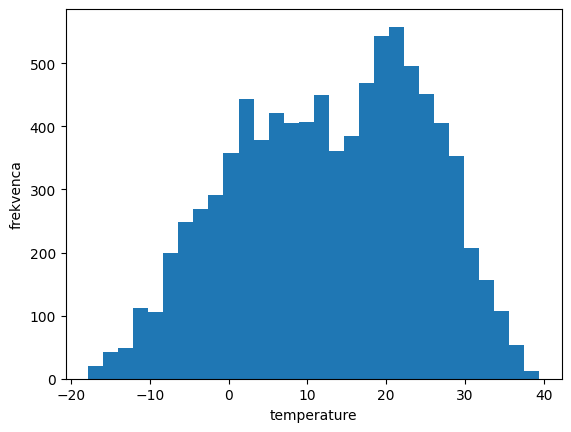

In [5]:
# histogram temperature
plt.hist(df['temperature'].dropna(), bins=30)
plt.xlabel('temperature')
plt.ylabel('frekvenca')
plt.show()

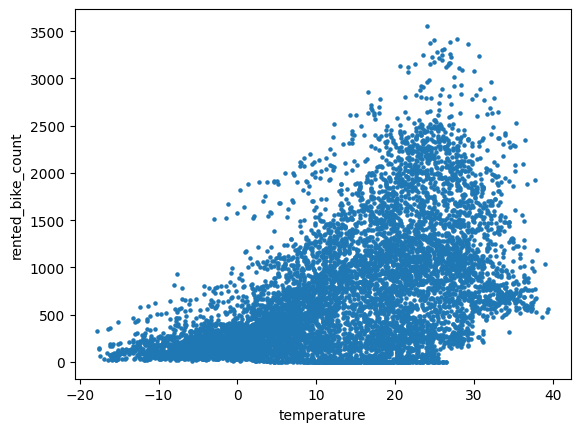

In [6]:
# graf raztrosa
plt.scatter(df['temperature'], df['rented_bike_count'], s=5)
plt.xlabel('temperature')
plt.ylabel('rented_bike_count')
plt.show()

In [7]:
# vhodne in ciljna spremenljivka, delitev 70/30
X = df.drop(columns='rented_bike_count')
y = df['rented_bike_count']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1234)

In [8]:
# zapolnitev manjkajocih z povprecji ucne mnozice in kodiranje kategoricnih
num_cols = X_train.select_dtypes(include='number').columns
means = X_train[num_cols].mean()
X_train = X_train.fillna(means)
X_test = X_test.fillna(means)

X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True).reindex(columns=X_train.columns, fill_value=0)

In [9]:
# ucenje modela
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [10]:
# napovedi in metrike na testni mnozici
pred = model.predict(X_test)
print('MAE:', mean_absolute_error(y_test, pred))
print('MSE:', mean_squared_error(y_test, pred))
print('R2:', r2_score(y_test, pred))
print('EVS:', explained_variance_score(y_test, pred))

MAE: 330.1994570694208
MSE: 193318.25943145508
R2: 0.5538884099113411
EVS: 0.5541991422949297


# Interpretacija

Model na testni mnozici dosega MAE 330, MSE 193318, R2 0,554 in EVS 0,554. Razlozi torej okoli 55 % variance izposoje, povprecna napaka (330 koles na uro) pa je skoraj polovica povprecne izposoje (705). R2 in EVS sta enaka, zato model nima sistematicnega odklona. Linearna regresija ne zajame nelinearnih odnosov (npr. vpliv ure dneva), zato so nekatere napovedi celo negativne. Model je povprecen; boljsi bi bil z nelinearnim modelom (npr. nakljucni gozd), saj linearna regresija ne zajame odvisnosti od ure in temperature.

In [11]:
# ucenje knn modelov z razlicnimi k in primerjalna tabela z linearno regresijo
from sklearn.neighbors import KNeighborsRegressor

rezultati = [{
    "Model": "Linear Regression",
    "MAE": mean_absolute_error(y_test, pred),
    "MSE": mean_squared_error(y_test, pred),
    "R2": r2_score(y_test, pred),
    "EVS": explained_variance_score(y_test, pred)
}]

for k in [3, 5, 10]:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train, y_train)
    p = knn.predict(X_test)
    rezultati.append({
        "Model": f"KNN (k={k})",
        "MAE": mean_absolute_error(y_test, p),
        "MSE": mean_squared_error(y_test, p),
        "R2": r2_score(y_test, p),
        "EVS": explained_variance_score(y_test, p)
    })

tabela = pd.DataFrame(rezultati)
tabela

,Model,MAE,MSE,R2,EVS
0,Linear Regression,330.199457,193318.259431,0.553888,0.554199
1,KNN (k=3),308.719812,212280.354854,0.510130,0.510137
2,KNN (k=5),306.625266,198974.051111,0.540837,0.540951
3,KNN (k=10),314.788661,201072.434871,0.535994,0.536143


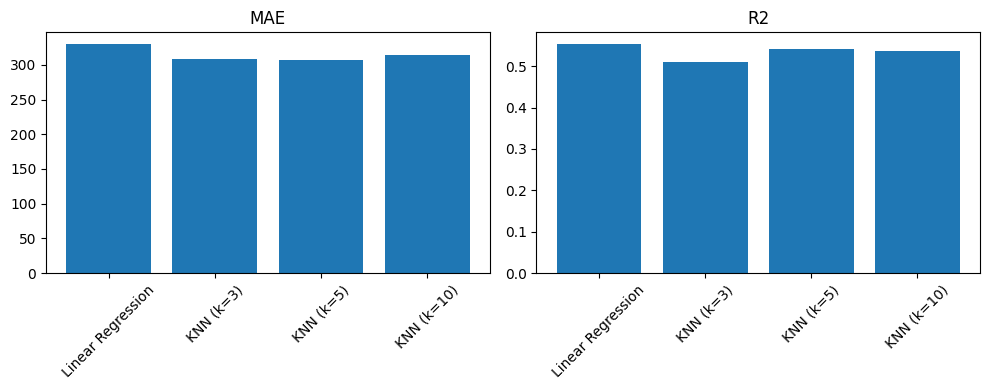

In [12]:
# graficna primerjava rezultatov z locenimi stolpicnimi grafi
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.bar(tabela["Model"], tabela["MAE"])
plt.title("MAE")
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
plt.bar(tabela["Model"], tabela["R2"])
plt.title("R2")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Komentar dodatnega dela

Pri modelih KNN ima najnizji MAE model s k=5 (306,6), pri k=3 pa je napaka nekoliko vecja zaradi prevelikega prilagajanja posameznim tockam (sumu), pri k=10 pa zaradi prevelikega glajenja. V primerjavi z linearno regresijo imajo vsi modeli KNN nekoliko nizji MAE, vendar ima linearna regresija nekoliko boljsi R2 (0,554 proti 0,541 pri k=5) in nizji MSE. Glavni razlog, da KNN ni znatno boljsi, je odsotnost skaliranja znacilk, zaradi cesar imajo spremenljivke z vecjimi razponi vrednosti (npr. vidljivost) prevelik vpliv na izracun razdalj.